<a href="https://colab.research.google.com/github/Faiva-404/PCVK_Ganjil_2026/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Faiva Puspa Sahara (06)
> MODUL P10 – Dasar - Dasar Deteksi Obyek

D. TUGAS PRAKTIKUM

D1. Praktikum Deteksi Objek Dasar

In [13]:
#import library yang dibutuhkan
import cv2 as cv
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood
from PIL import Image
from scipy.signal import fftconvolve
from scipy.ndimage import maximum_filter
from matplotlib.patches import Rectangle
import os

In [2]:
#akses drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


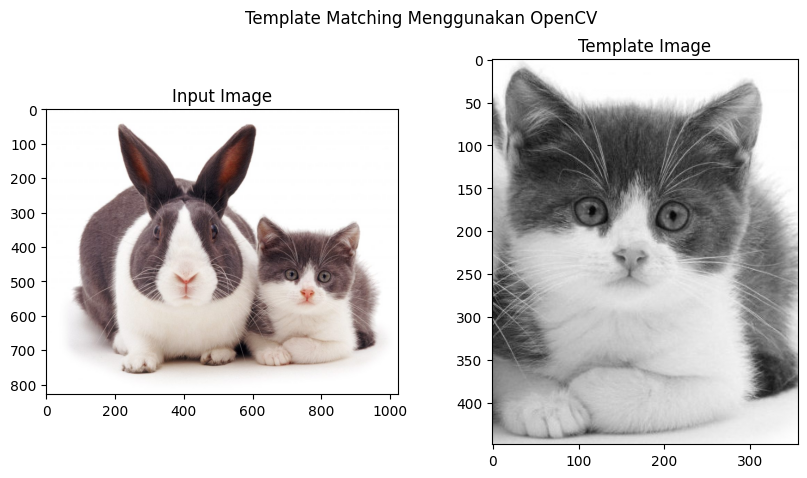

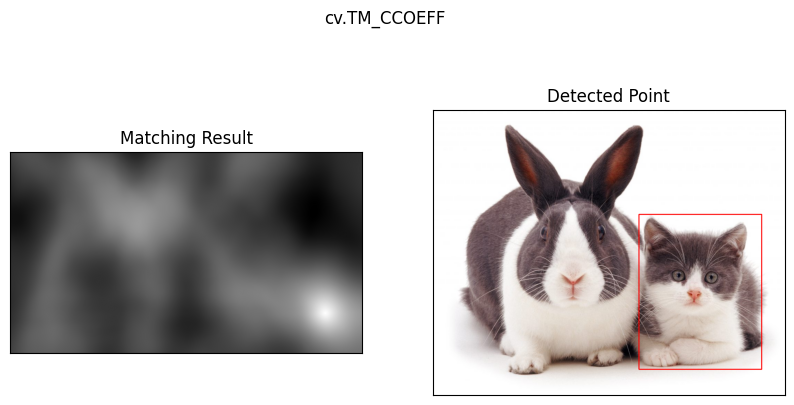

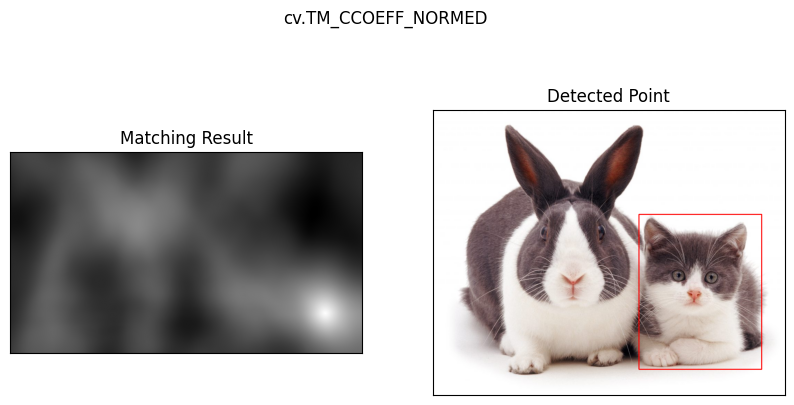

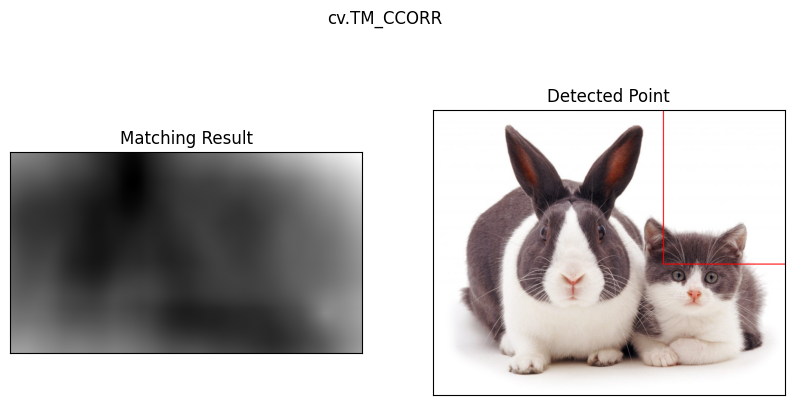

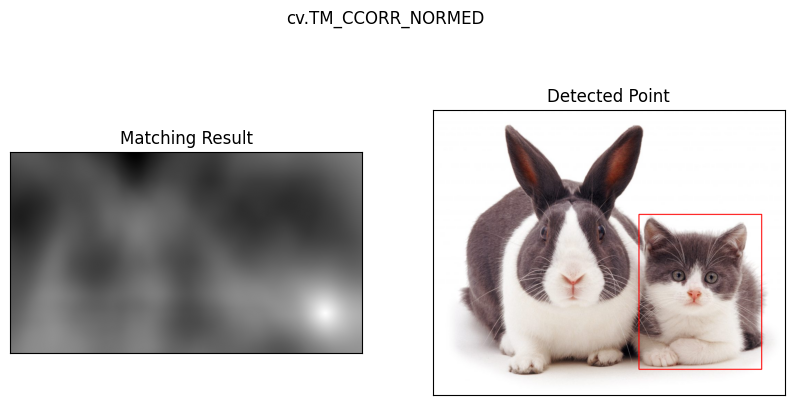

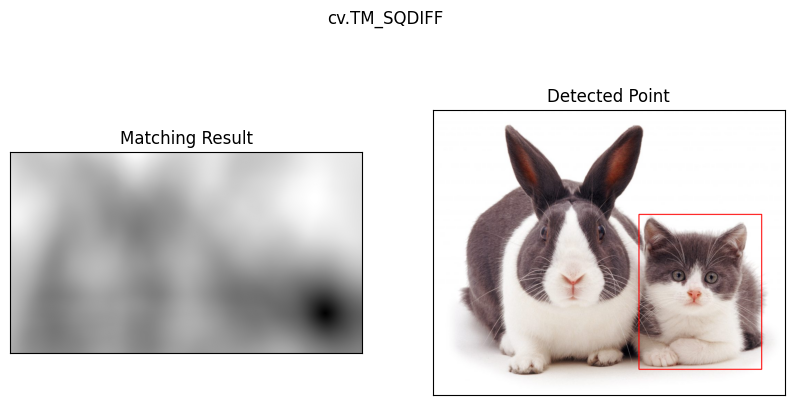

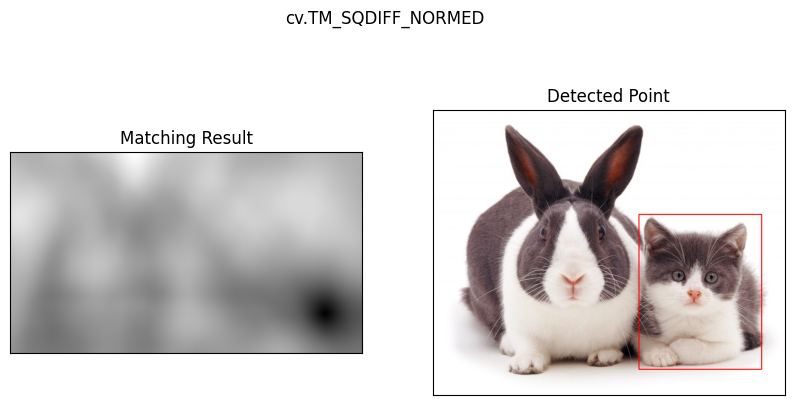

In [8]:
# Template Matching Menggunakan OpenCV
image = cv.imread('/content/drive/MyDrive/SEMESTER 5/Citra/cats_and_bunnies.jpg')
image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
image_gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
templ = cv.imread('/content/drive/MyDrive/SEMESTER 5/Citra/cat2_templatejpg.jpg', 0)
w, h = templ.shape[::-1]

# List metode template matching
methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
            'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

# Menampilkan input image dan template image
plt.figure(figsize = (10,5))
plt.subplot(121),plt.imshow(image)
plt.title('Input Image')
plt.subplot(122),plt.imshow(templ,cmap = 'gray')
plt.title('Template Image')
plt.suptitle("Template Matching Menggunakan OpenCV")
plt.show()

# Loop setiap metode
for meth in methods:
    output_image = image.copy()
    img = image_gray.copy()
    method = eval(meth)
    # Apply template Matching
    res = cv.matchTemplate(img,templ,method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)
    # If the method is TM_SQDIFF or TM_SQDIFF_NORMED, take minimum
    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)
    cv.rectangle(output_image,top_left, bottom_right, (255,0,0), 2)

    plt.figure(figsize = (10,5))
    plt.subplot(1,2,1),plt.imshow(res,cmap = 'gray')
    plt.title('Matching Result'), plt.xticks([]), plt.yticks([])
    plt.subplot(1,2,2),plt.imshow(output_image)
    plt.title('Detected Point'), plt.xticks([]), plt.yticks([])
    plt.suptitle(meth)
    plt.show()

3. Implementasikan konsep template matching tanpa menggunakan library OpenCV untuk
multiple object, menggunakan gambar bahrain.jpg untuk citra masukan dan bahrain_template.jpg sebagai citra template

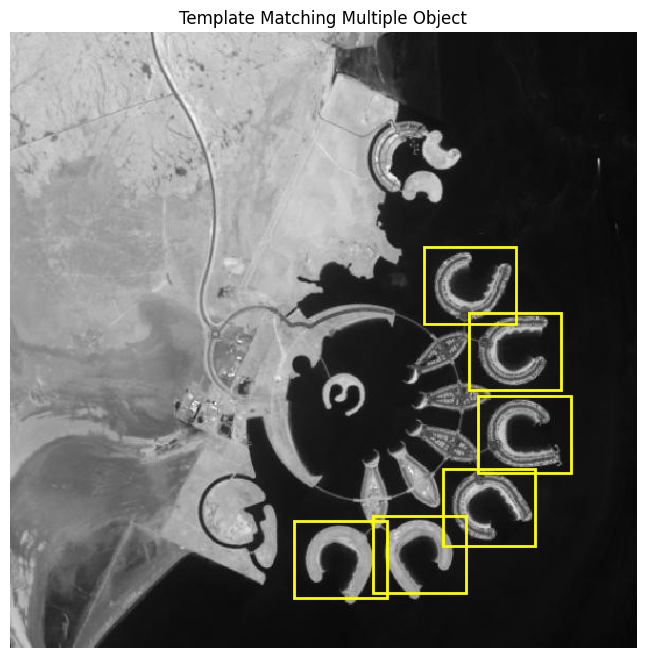

Jumlah objek terdeteksi: 6


In [14]:
# Membaca gambar
path = '/content/drive/MyDrive/PCVK/Images'

img = np.array(
    Image.open(os.path.join(path, '/content/drive/MyDrive/SEMESTER 5/Citra/bahrain.jpg')).convert('L'),
    dtype=np.float32) / 255.0

template = np.array(
    Image.open(os.path.join(path, '/content/drive/MyDrive/SEMESTER 5/Citra/bahrain-template.jpg')).convert('L'),
    dtype=np.float32) / 255.0

# Ukuran gambar dan template
h, w = template.shape
n = h * w

# Menghitung korelasi antara gambar dan template
sum_it = fftconvolve(img, template[::-1, ::-1], mode='valid')

# Menghitung jumlah piksel menggunakan integral image
def integral_image(image):
    return np.pad(
        np.cumsum(np.cumsum(image, axis=0), axis=1),
        ((1, 0), (1, 0)))

integral = integral_image(img)
integral_sq = integral_image(img ** 2)

# Menghitung jumlah piksel pada setiap area
sum_i = (
    integral[h:, w:] - integral[:-h, w:]
    - integral[h:, :-w] + integral[:-h, :-w])

sum_i2 = (
    integral_sq[h:, w:] - integral_sq[:-h, w:]
    - integral_sq[h:, :-w] + integral_sq[:-h, :-w])

# Normalized Cross Correlation
sum_t = np.sum(template)
sum_t2 = np.sum(template ** 2)

numerator = sum_it - (sum_i * sum_t / n)

denominator = np.sqrt(
    np.maximum(
        (sum_i2 - sum_i ** 2 / n) *
        (sum_t2 - sum_t ** 2 / n),
        0))

result = np.zeros_like(numerator)

np.divide(
    numerator,
    denominator,
    out=result,
    where=denominator > 1e-10)

# Mencari beberapa lokasi objek yang cocok
threshold = 0.45

local_max = maximum_filter(
    result,
    size=(max(3, h // 2), max(3, w // 2)))

candidates = np.argwhere(
    (result >= threshold) & (result == local_max))

# Mengurutkan berdasarkan nilai kecocokan tertinggi
scores = result[candidates[:, 0], candidates[:, 1]]
order = np.argsort(scores)[::-1]

# Non-Maximum Suppression
detections = []

for idx in order:
    y, x = candidates[idx]

    box = (x, y, x + w, y + h)

    keep = True

    for prev in detections:
        xx1 = max(box[0], prev[0])
        yy1 = max(box[1], prev[1])
        xx2 = min(box[2], prev[2])
        yy2 = min(box[3], prev[3])

        intersection = max(0, xx2 - xx1) * max(0, yy2 - yy1)

        area = w * h
        iou = intersection / (2 * area - intersection)

        if iou > 0.25:
            keep = False
            break
    if keep:
        detections.append(box)

# Menampilkan hasil deteksi
fig, ax = plt.subplots(figsize=(10, 8))

ax.imshow(img, cmap='gray')

for x1, y1, x2, y2 in detections:
    rect = Rectangle(
        (x1, y1), w, h,
        linewidth=2,
        edgecolor='yellow',
        facecolor='none')
    ax.add_patch(rect)

ax.set_title('Template Matching Multiple Object')
ax.axis('off')

plt.show()

print("Jumlah objek terdeteksi:", len(detections))

4. Implementasikan metode Sobel Edge Detection, Canny Edge Detection, dan Laplacian Edge Detection pada OpenCV dengan menggunakan gambar car-park.jpg,

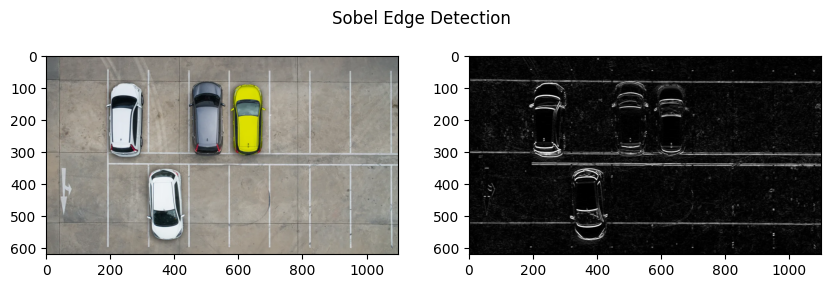

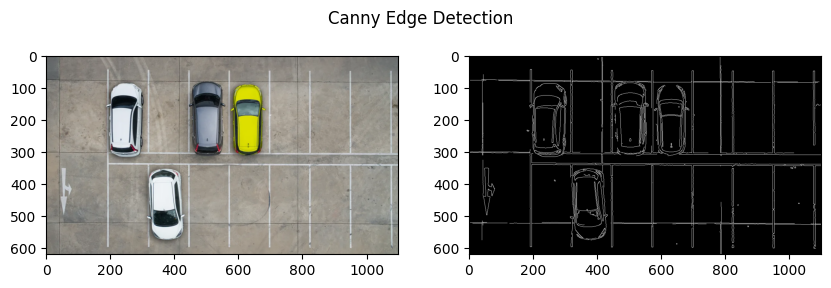

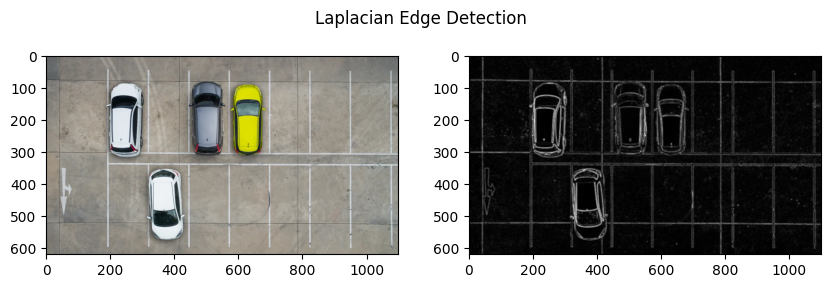

In [15]:
# Edge Detection Menggunakan OpenCV
image = cv.imread('/content/drive/MyDrive/SEMESTER 5/Citra/car-park.jpg')
image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
image_gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

# remove noise
img = cv.GaussianBlur(image_gray,(3,3),0)
sobel = img.copy()
canny = img.copy()
laplacian = img.copy()
title = ["Sobel Edge Detection", "Canny Edge Detection", "Laplacian Edge Detection"]

# Edge detection menggunakan openCV
sobel = cv.Sobel(src=sobel, ddepth=cv.CV_64F, dx=0, dy=1, ksize=3) # Menggunakan sobel y filter
sobel = cv.convertScaleAbs(sobel) # konversi citra ke uint8
canny = cv.Canny(image=canny, threshold1=100, threshold2=200)
laplacian = cv.Laplacian(laplacian,cv.CV_64F, ksize=3)
laplacian =  cv.convertScaleAbs(laplacian) # konversi citra ke uint8
images = [sobel, canny, laplacian]

for i in range(3):
  plt.figure(figsize = (10,3))
  plt.subplot(121),plt.imshow(image)
  plt.subplot(122),plt.imshow(images[i], 'gray')
  plt.suptitle(title[i])
  plt.show()

5. Implementasikan metode Harris Corner Detection dan Shi-Tomasi
Detection pada OpenCV dengan menggunakan gambar chess-board.jpg,

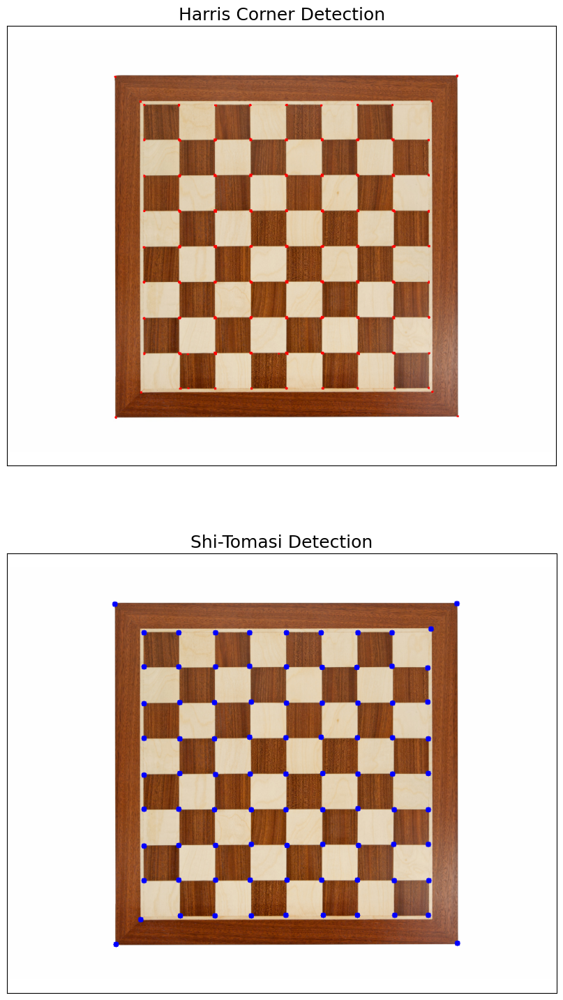

In [18]:
# Implementasi metode Harris Corner Detection dan Shi-Tomasi Detection pada OpenCV
image = cv.imread('/content/drive/MyDrive/SEMESTER 5/Citra/chess-board.jpg')
image = cv.cvtColor(image, cv.COLOR_BGR2RGB)

harris = image.copy()
shi = image.copy()

image_gray = cv.cvtColor(harris, cv.COLOR_RGB2GRAY)
image_gray = np.float32(image_gray)

gray = cv.cvtColor(shi, cv.COLOR_RGB2GRAY)

# Implementasi Harris Corner Detection OpenCV
corner = cv.cornerHarris(image_gray, 2, 3, 0.04)
corner = cv.dilate(corner, None)
harris[corner > 0.01 * corner.max()] = [255, 0, 0]

# Implementasi Shi-Tomasi Detection OpenCV
corners = cv.goodFeaturesToTrack(gray, 85, 0.01, 10)
corners = np.intp(corners)

for i in corners:
    x, y = i.ravel()
    cv.circle(shi, (x, y), 5, (0, 0, 255), -1)

# Membuat figure
plt.figure(figsize=(15, 18))

plt.subplot(211), plt.imshow(harris)
plt.title('Harris Corner Detection', fontsize=18)
plt.xticks([]), plt.yticks([])

plt.subplot(212), plt.imshow(shi)
plt.title('Shi-Tomasi Detection', fontsize=18)
plt.xticks([]), plt.yticks([])

plt.show()

6. Implementasikan metode Hough Transform pada OpenCV dengan menggunakan gambar sudoku.jpg

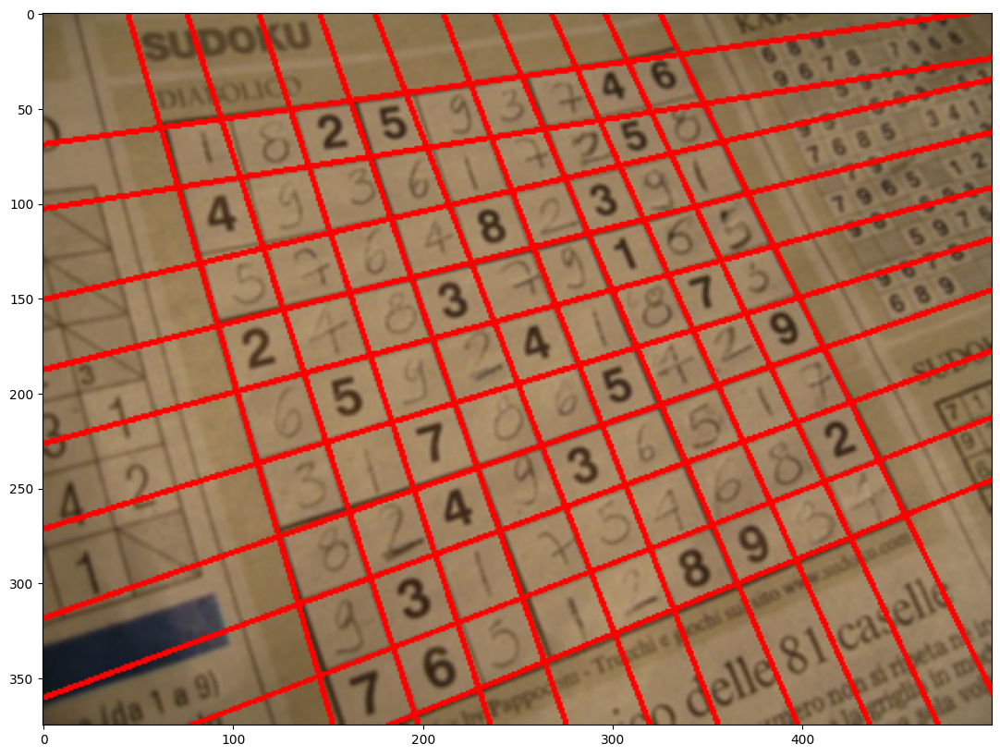

In [19]:
# Implementasi metode Hough Transform pada OpenCV
image = cv.imread('/content/drive/MyDrive/SEMESTER 5/Citra/sudoku.jpg')
image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
image_gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

# Menerapkan Canny Edge Detection
edges = cv.Canny(image_gray,50,250,apertureSize = 3)

# Dilasi gambar tepi (Canny bisa menemukan kedua tepi pemisah pada grid sebagai tepi yang
# berbeda, dilatasi dapat membuat kedua tepi ini bergabung lagi)
se = np.ones((3,3))
edges = cv.dilate(edges, se)

# Erosi (setelah proses dilasi, garis border menjadi tebal sehingga Hough akan mendeteksi banyak garis)
se = np.ones((3,3))
edges = cv.erode(edges, se)

# Menerapkan  HoughLines dengan fungsi cv2.HoughLines() pada OpenCV
lines = cv.HoughLines(edges,1,np.pi/180,220)

# Menggabungkan garis yang mirip (similar)
rho_threshold = 15
theta_threshold = 0.1

similar_lines = {i : [] for i in range(len(lines))}
for i in range(len(lines)):
  for j in range (len (lines)):
    if i == j:
      continue

    rho_i, theta_i = lines[i][0]
    rho_j, theta_j = lines[j][0]
    if abs(rho_i - rho_j) < rho_threshold and abs (theta_i - theta_j) < theta_threshold:
      similar_lines[i].append(j)

indices = [i for i in range(len(lines))]
indices.sort(key=lambda x: len(similar_lines[x]))

line_flags = len(lines) *[True]
for i in range(len(lines) - 1):
  if not line_flags [indices[i]]:
    continue

  for j in range(i + 1, len(lines)):
    if not line_flags[indices[j]]:
      continue
    rho_i, theta_i = lines[indices[i]][0]
    rho_j, theta_j = lines[indices[j]][0]
    if abs(rho_i - rho_j) < rho_threshold and abs(theta_i - theta_j) < theta_threshold:
      line_flags [indices[j]] = False

filtered_lines = []
for i in range(len(lines)):
  if line_flags[i]:
    filtered_lines.append(lines[i])

for line in filtered_lines:
    rho,theta = line[0]
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a*rho
    y0 = b*rho
    x1 = int(x0 + 1000*(-b))
    y1 = int(y0 + 1000*(a))
    x2 = int(x0 - 1000*(-b))
    y2 = int(y0 - 1000*(a))
    cv.line(image,(x1,y1),(x2,y2),(255,0,0),2)

plt.figure(figsize = (15,10))
plt.imshow(image)

7. Implementasikan fungsi findContours() pada OpenCV untuk contour detection dengan menggunakan gambar laptop.jpg

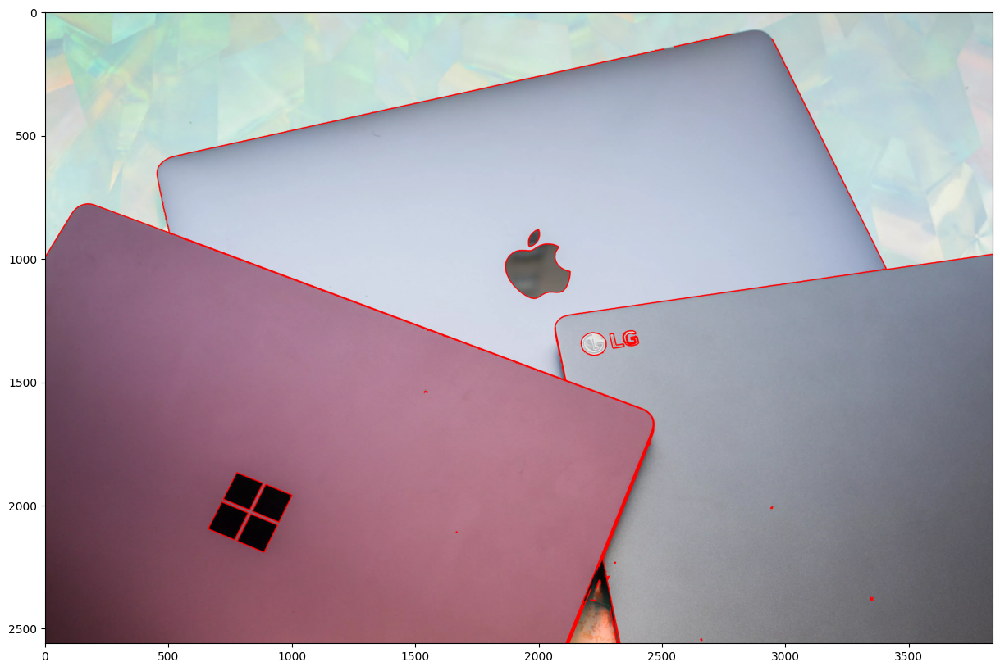

In [20]:
# Implementasi fungsi findContours() pada OpenCV
image = cv.imread('/content/drive/MyDrive/SEMESTER 5/Citra/laptop.jpg')
image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
image_gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

# Menerapkan Canny Edge Detection
edged = cv.Canny(image_gray, 30, 200)

# Menerapkan fungsi findContours() openCV
contours, hierarchy = cv.findContours(edged,
    cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)
cv.drawContours(image, contours, -1, (255, 0, 0), 3)

plt.figure(figsize = (15,10))
plt.imshow(image)



> D2. Praktikum Feature Matching dan Face Detection

8. Lakukan Face Detection untuk image object lain yang tersedia pada
(/images/facedet)

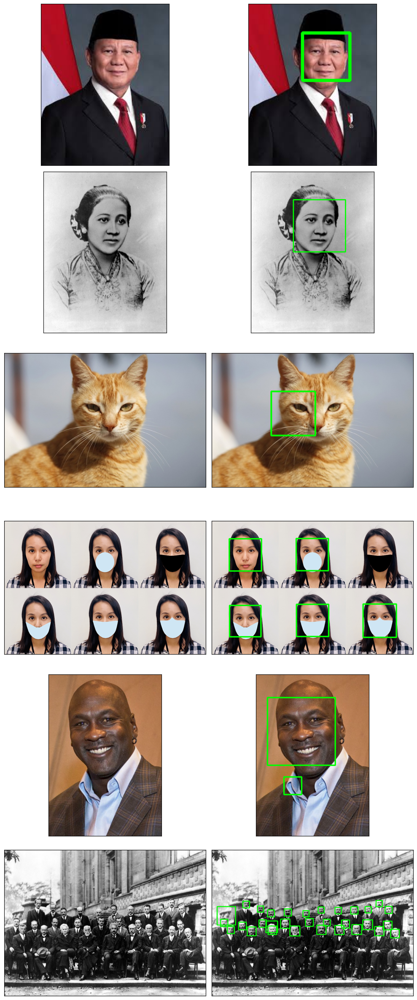

In [23]:
# Path folder facedet tempat menyimpan gambar
folder_path = '/content/drive/MyDrive/SEMESTER 5/Citra/facedet'

# Load classifier wajah default
face_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_default.xml')

# Urutan gambar sesuai dengan modul praktikum
images_list = ['prabowo.jpg', 'kartini.jpg', 'mycat.jpg', 'mask.png', 'mjordan.jpg', 'solvayconf.jpg']

# Membuat figure grid 6 baris x 2 kolom
plt.figure(figsize=(10, 24))

for i, img_name in enumerate(images_list):
    img_path = os.path.join(folder_path, img_name)

    # Baca gambar
    img_bgr = cv.imread(img_path)
    if img_bgr is None:
        print(f"Gambar {img_name} tidak ditemukan pada path {img_path}")
        continue

    img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

    # Kolom 1: Tampilkan Gambar Asli (Grayscale/RGB sesuai modul)
    plt.subplot(6, 2, i * 2 + 1)
    if len(img_bgr.shape) == 3:
        plt.imshow(cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB))
    else:
        plt.imshow(img_bgr, cmap='gray')
    plt.xticks([]), plt.yticks([])

    # Deteksi Wajah
    # Parameter disesuaikan agar cocok mendeteksi wajah di solvayconf maupun foto tunggal
    faces = face_cascade.detectMultiScale(
        img_gray,
        scaleFactor=1.1,
        minNeighbors=5 if img_name != 'solvayconf.jpg' else 3,
        minSize=(15, 15)
    )

    # Buat salinan gambar untuk menggambar bounding box
    img_out = img_bgr.copy()
    for (x, y, w, h) in faces:
        cv.rectangle(img_out, (x, y), (x + w, y + h), (0, 255, 0), 3)

    # Kolom 2: Tampilkan Hasil Deteksi
    plt.subplot(6, 2, i * 2 + 2)
    plt.imshow(cv.cvtColor(img_out, cv.COLOR_BGR2RGB))
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

9. Pada soal sebelumnya, wajah kucing tidak bisa dideteksi dengan baik. Lakukan
deteksi wajah kucing hingga muncul rectangle pada bagian wajah kucing.
Petunjuk pada soal ini, perhatikan pretrained features yang telah disediakan
OpenCV.

File haarcascade_frontalcatface.xml tidak ditemukan, mengunduh secara otomatis...
--2026-11-02 02:21:41--  https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalcatface.xml
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 411388 (402K) [text/plain]
Saving to: ‘/content/drive/MyDrive/PCVK/Images/haarcascades/haarcascade_frontalcatface.xml’

haarcascade_frontal 100%[===================>] 401.75K  --.-KB/s    in 0.06s   

2026-11-02 02:21:42 (6.75 MB/s) - ‘/content/drive/MyDrive/PCVK/Images/haarcascades/haarcascade_frontalcatface.xml’ saved [411388/411388]



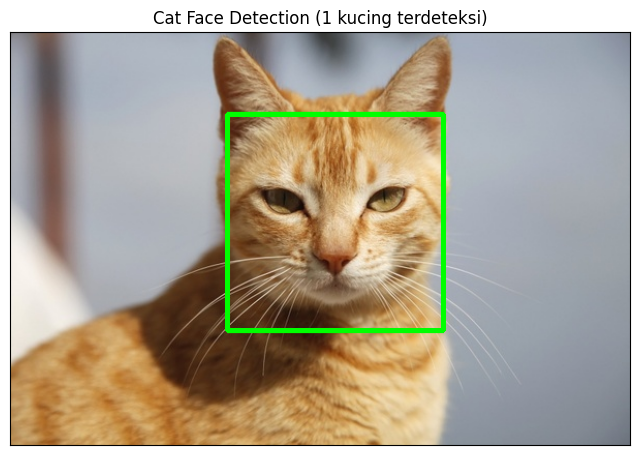

In [27]:
# 1. Path ke file XML cascade kucing
xml_path = '/content/drive/MyDrive/PCVK/Images/haarcascades/haarcascade_frontalcatface.xml'

# Opsi otomatis: Unduh file XML jika file belum ada di Google Drive
if not os.path.exists(xml_path):
    print("File haarcascade_frontalcatface.xml tidak ditemukan, mengunduh secara otomatis...")
    !wget -P /content/drive/MyDrive/PCVK/Images/haarcascades/ https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalcatface.xml

# 2. Load Cascade Classifier
cat_cascade = cv.CascadeClassifier(xml_path)

# Cek apakah classifier berhasil di-load
if cat_cascade.empty():
    print("Error: Gagal memuat Cascade Classifier. Pastikan path file XML sudah benar!")
else:
    # 3. Read Gambar Kucing
    img_path = '/content/drive/MyDrive/SEMESTER 5/Citra/facedet/mycat.jpg'
    img_cat = cv.imread(img_path)

    if img_cat is None:
        print(f"Error: Gambar tidak ditemukan di {img_path}")
    else:
        gray_cat = cv.cvtColor(img_cat, cv.COLOR_BGR2GRAY)

        # 4. Deteksi Wajah Kucing
        cats = cat_cascade.detectMultiScale(gray_cat, scaleFactor=1.1, minNeighbors=3)

        # 5. Gambar Bounding Box
        for (x, y, w, h) in cats:
            cv.rectangle(img_cat, (x, y), (x+w, y+h), (0, 255, 0), 3)

        # 6. Tampilkan Hasil
        plt.figure(figsize=(8, 6))
        plt.imshow(cv.cvtColor(img_cat, cv.COLOR_BGR2RGB))
        plt.title(f'Cat Face Detection ({len(cats)} kucing terdeteksi)')
        plt.xticks([]), plt.yticks([])
        plt.show()

10. Cobakan juga untuk eyes detection pada wajah Pak Prabowo:

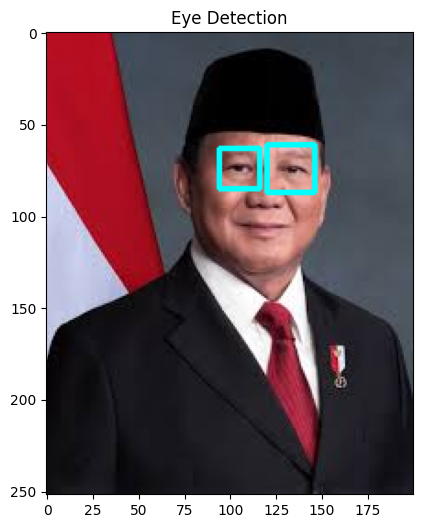

In [31]:
eye_cascade = cv.CascadeClassifier('/content/drive/MyDrive/SEMESTER 5/Citra/haarcascades/haarcascade_eye.xml')
prabowo = cv.imread('/content/drive/MyDrive/SEMESTER 5/Citra/facedet/prabowo.jpg')
gray_prabowo = cv.cvtColor(prabowo, cv.COLOR_BGR2GRAY)

eyes = eye_cascade.detectMultiScale(gray_prabowo, scaleFactor=1.1, minNeighbors=5)

for (ex, ey, ew, eh) in eyes:
    cv.rectangle(prabowo, (ex, ey), (ex+ew, ey+eh), (255, 255, 0), 2)

plt.figure(figsize=(6, 6))
plt.imshow(cv.cvtColor(prabowo, cv.COLOR_BGR2RGB))
plt.title('Eye Detection')
plt.show()

11. Lakukan deteksi senyuman pada gambar people:

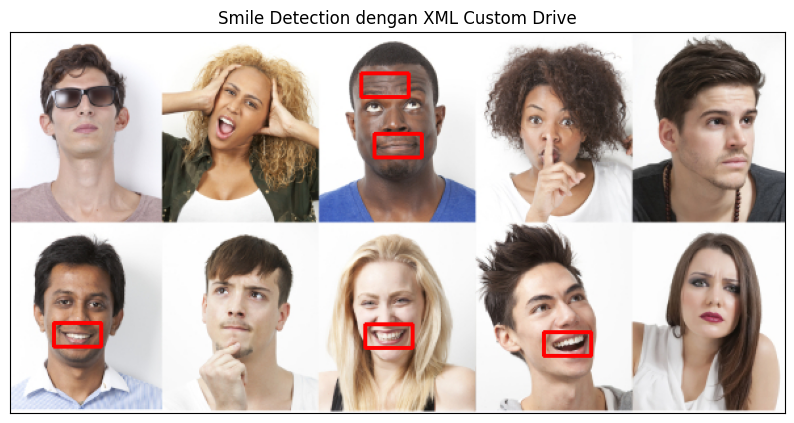

In [37]:
# 1. Path ke XML Wajah (bawaan OpenCV) & XML Senyum milikmu
face_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_default.xml')
smile_cascade = cv.CascadeClassifier('/content/drive/MyDrive/SEMESTER 5/Citra/haarcascades/haarcascade_smile.xml')

# Pastikan file XML senyum berhasil dimuat
if smile_cascade.empty():
    print("Error: Gagal memuat haarcascade_smile.xml dari path drive kamu!")
else:
    # 2. Baca Gambar
    img_path = '/content/drive/MyDrive/SEMESTER 5/Citra/facedet/people.jpg'
    img_smile = cv.imread(img_path)
    gray_smile = cv.cvtColor(img_smile, cv.COLOR_BGR2GRAY)

    # 3. Deteksi Wajah Terlebih Dahulu
    faces = face_cascade.detectMultiScale(gray_smile, scaleFactor=1.1, minNeighbors=5)

    # 4. Deteksi Senyum di dalam ROI Wajah
    for (x, y, w, h) in faces:
        roi_gray = gray_smile[y:y+h, x:x+w]
        roi_color = img_smile[y:y+h, x:x+w]

        # Parameter minNeighbors disesuaikan ke 3 agar senyum mudah terdeteksi
        smiles = smile_cascade.detectMultiScale(
            roi_gray,
            scaleFactor=1.3,
            minNeighbors=3,
            minSize=(15, 15)
        )

        # Gambar kotak merah untuk senyum
        for (sx, sy, sw, sh) in smiles:
            cv.rectangle(roi_color, (sx, sy), (sx+sw, sy+sh), (0, 0, 255), 2)

    # 5. Tampilkan Hasil
    plt.figure(figsize=(10, 8))
    plt.imshow(cv.cvtColor(img_smile, cv.COLOR_BGR2RGB))
    plt.title('Smile Detection dengan XML Custom Drive')
    plt.xticks([]), plt.yticks([])
    plt.show()

12. Lakukan Face Tracking menggunakan Google Colab. Petunjuk, Tutorial lengkap
tentang akses kamera dan FaceDetection

<IPython.core.display.Javascript object>

Foto berhasil diambil!


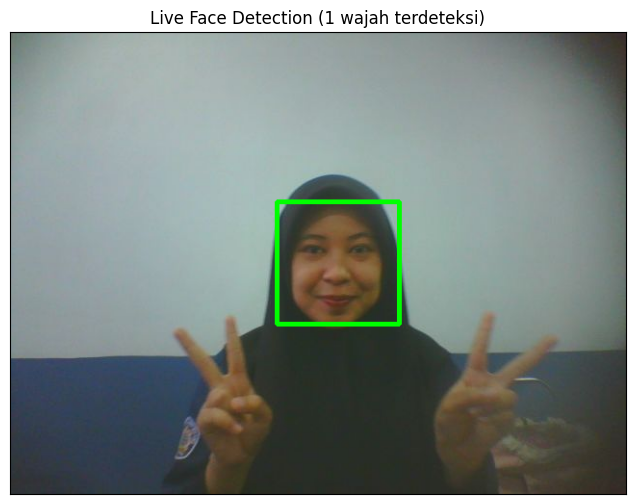

In [41]:
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

def take_photo(filename='webcam.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'CAPTURE PHOTO';
      capture.style.display = 'block';
      capture.style.margin = '10px 0';
      capture.style.padding = '8px 16px';
      capture.style.backgroundColor = '#4CAF50';
      capture.style.color = 'white';
      capture.style.border = 'none';
      capture.style.borderRadius = '4px';
      capture.style.cursor = 'pointer';

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      div.appendChild(capture);
      video.srcObject = stream;
      await video.play();

      // Resize canvas sesuai ukuran video
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Tunggu hingga tombol diklik
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);

      stream.getTracks().forEach(track => track.stop());
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

try:
  # 1. Ambil Foto dari Webcam
  filename = take_photo()
  print('Foto berhasil diambil!')

  # 2. Deteksi Wajah dengan OpenCV
  face_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_default.xml')
  frame = cv.imread(filename)
  gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
  faces = face_cascade.detectMultiScale(gray, scaleFactor=1.3, minNeighbors=5)

  for (x, y, w, h) in faces:
      cv.rectangle(frame, (x, y), (x+w, y+h), (0, 255, 0), 3)

  # 3. Tampilkan Hasil Deteksi
  plt.figure(figsize=(8, 6))
  plt.imshow(cv.cvtColor(frame, cv.COLOR_BGR2RGB))
  plt.title(f'Live Face Detection ({len(faces)} wajah terdeteksi)')
  plt.xticks([]), plt.yticks([])
  plt.show()

except Exception as err:
  print("Gagal mengkases kamera:", err)
  print("Pastikan kamu telah mengizinkan (Allow) akses kamera pada browser!")

13. Lakukan Blurring pada bagian wajah yang terdeteksi. Berikut contoh keluaran
yang diharapkan. Petunjuk: anda dapat menggunakan cv.medianBlur untuk
melakukan Blurring

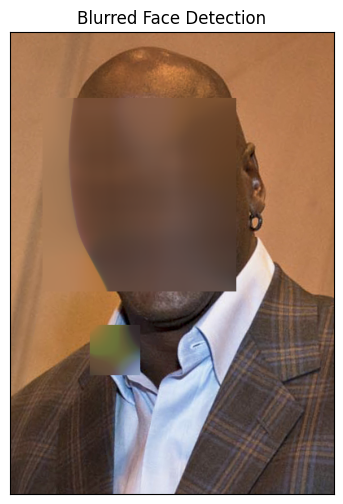

In [44]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

# 1. Load Classifier Wajah
face_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_default.xml')

# 2. Read Gambar (Sesuaikan path dengan lokasi folder di Drive kamu)
img_path = '/content/drive/MyDrive/SEMESTER 5/Citra/facedet/mjordan.jpg'
img_blur = cv.imread(img_path)

# Cek apakah gambar berhasil dibaca
if img_blur is None:
    print(f"Error: Gambar tidak ditemukan di path: {img_path}")
else:
    # 3. Konversi ke Grayscale & Deteksi Wajah
    gray = cv.cvtColor(img_blur, cv.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=4)

    # 4. Blur Area Wajah yang Terdeteksi
    for (x, y, w, h) in faces:
        # Crop Region of Interest (ROI) Wajah
        roi = img_blur[y:y+h, x:x+w]

        # Blurring menggunakan medianBlur (ukuran kernel ganjil, misal 99)
        blurred_roi = cv.medianBlur(roi, 99)

        # Timpa area wajah asli dengan area yang sudah diblur
        img_blur[y:y+h, x:x+w] = blurred_roi

    # 5. Tampilkan Hasil
    plt.figure(figsize=(6, 6))
    plt.imshow(cv.cvtColor(img_blur, cv.COLOR_BGR2RGB))
    plt.title('Blurred Face Detection')
    plt.xticks([]), plt.yticks([])
    plt.show()

14. Mengolah gambar KTM masing-masing

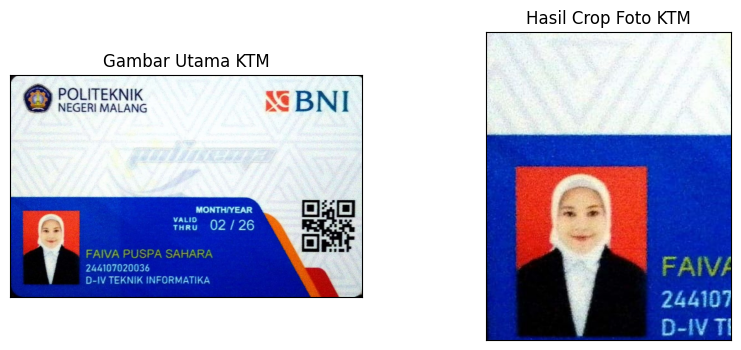

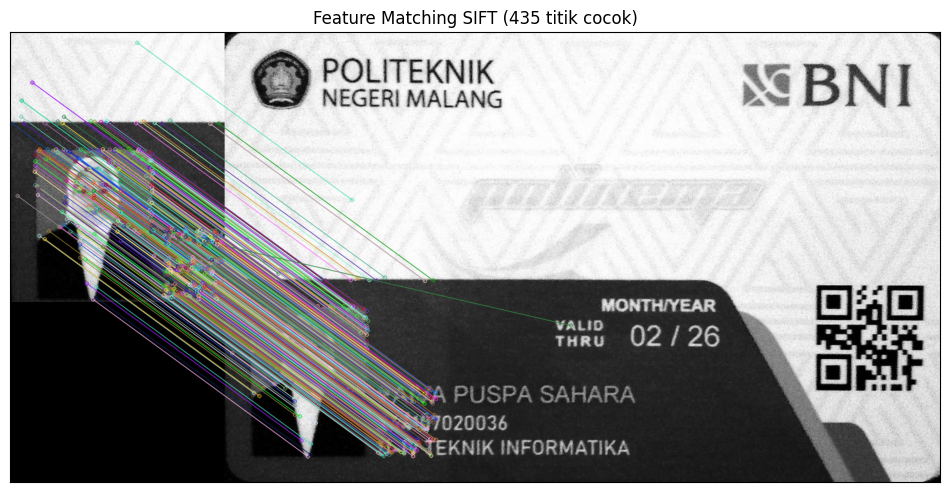

In [48]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

# 1. Read Gambar Utama KTM
img_path = '/content/drive/MyDrive/SEMESTER 5/Citra/KTM (Kartu Tanda Mahasiswa).jpg'
ktm_img = cv.imread(img_path)

if ktm_img is None:
    print(f"Error: Gambar tidak ditemukan di {img_path}")
else:
    # Dimensi Gambar KTM
    h_img, w_img, _ = ktm_img.shape

    # -------------------------------------------------------------
    # a & b. Crop Foto Pasfoto KTM (Sebelah Kiri Bawah)
    # -------------------------------------------------------------
    # Sumbu Y: Dari 35% sampai 95% tinggi gambar (bawah)
    # Sumbu X: Dari 0% sampai 30% lebar gambar (kiri)
    y1, y2 = int(h_img * 0.35), int(h_img * 0.95)
    x1, x2 = int(w_img * 0.0), int(w_img * 0.30)

    foto_ktm = ktm_img[y1:y2, x1:x2]

    # Plot Gambar Utama KTM dan Hasil Crop Pasfoto
    plt.figure(figsize=(10, 4))
    plt.subplot(121), plt.imshow(cv.cvtColor(ktm_img, cv.COLOR_BGR2RGB)), plt.title('Gambar Utama KTM')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(cv.cvtColor(foto_ktm, cv.COLOR_BGR2RGB)), plt.title('Hasil Crop Foto KTM')
    plt.xticks([]), plt.yticks([])
    plt.show()

    # -------------------------------------------------------------
    # c. Feature Matching SIFT
    # -------------------------------------------------------------
    gray_ktm = cv.cvtColor(ktm_img, cv.COLOR_BGR2GRAY)
    gray_template = cv.cvtColor(foto_ktm, cv.COLOR_BGR2GRAY)

    # Deteksi SIFT
    sift = cv.SIFT_create()
    kp1, des1 = sift.detectAndCompute(gray_template, None) # Template Foto Wajah
    kp2, des2 = sift.detectAndCompute(gray_ktm, None)      # Gambar KTM Utuh

    # Matcher
    bf = cv.BFMatcher()
    matches = bf.knnMatch(des1, des2, k=2)

    # Ratio Test
    good_matches = []
    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good_matches.append([m])

    # Visualisasi Match
    img_match = cv.drawMatchesKnn(gray_template, kp1, gray_ktm, kp2, good_matches, None, flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    plt.figure(figsize=(12, 6))
    plt.imshow(img_match)
    plt.title(f'Feature Matching SIFT ({len(good_matches)} titik cocok)')
    plt.xticks([]), plt.yticks([])
    plt.show()



> D3. Tugas Pengayaan : Pengenalan Karakter KTM dengan CNN

